# Conditional VAE with ChestXray14

This notebook applies PyHealth's image VAE to chest X-rays from the NIH ChestXray14 dataset. It uses the `infiltration` finding as a binary condition, trains the VAE to reconstruct images, and samples images conditioned on the two labels. A VAE reconstructs images; it is not trained here to predict the finding.

The first run downloads the first ChestXray14 image archive through PyHealth (4,999 images) and its label file. This is enough to try the workflow locally; the full dataset contains 112,120 images and requires substantially more storage. If the expected CSV and `images/` directory are already present, the setup cell reuses them without downloading again. `dev=True` limits processing to 1,000 patients after the data are available.

As another option, PyHealth supports the COVID-19 Radiography Database. This notebook does not download it. Download and extract the dataset from [Kaggle](https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database), then set `root` in `COVID19CXRDataset(root=...)` to the extracted `COVID-19_Radiography_Dataset` directory. That directory should contain the class folders and metadata spreadsheets (for example, `COVID/`, `Normal/`, `Lung_Opacity/`, `Viral Pneumonia/`, and their metadata files). You need a Kaggle account and must accept the dataset access terms on Kaggle first.

## 1. Configure data and load ChestXray14

We resize images to 64×64 grayscale to keep this example lighter. The setup cell asks PyHealth to download only the first archive; change `PARTIAL_DOWNLOAD` to `False` only if you intend to download the full dataset.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Dataset

from pyhealth.datasets import (
    ChestXray14Dataset,
    get_dataloader,
    split_by_patient,
)
from pyhealth.datasets.utils import collate_fn_dict_with_padding
from pyhealth.models import VAE
from pyhealth.processors import ImageProcessor
from pyhealth.tasks import ChestXray14BinaryClassification
from pyhealth.trainer import Trainer

DATA_ROOT = Path(
    os.environ.get("PYHEALTH_CHESTXRAY14_ROOT", "./data/chestxray14")
)
PARTIAL_DOWNLOAD = True  # First archive: 4,999 images. False downloads all 112,120.
DEV_MODE = True           # Process at most 1,000 patients.
DATA_AVAILABLE = (
    (DATA_ROOT / "Data_Entry_2017_v2020.csv").is_file()
    and (DATA_ROOT / "images").is_dir()
)
DOWNLOAD_DATA = not DATA_AVAILABLE  # Download once; reuse the local copy on reruns.

if DOWNLOAD_DATA:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
elif not DATA_AVAILABLE:
    raise FileNotFoundError(
        f"ChestXray14 files were not found under {DATA_ROOT}. Set "
        "PYHEALTH_CHESTXRAY14_ROOT to your local dataset directory, or set "
        "DOWNLOAD_DATA=True and choose whether to download the partial archive."
    )

base_dataset = ChestXray14Dataset(
    root=str(DATA_ROOT),
    download=DOWNLOAD_DATA,
    partial=PARTIAL_DOWNLOAD,
    dev=DEV_MODE,
)
print(f"ChestXray14 root: {DATA_ROOT}")

/Users/giovannidallolio/workspace/PyHealth/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1029 16:20:41.297000 40140 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Initializing ChestX-ray14 dataset from data/chestxray14 (dev mode: True)


No cache_dir given: PyHealth will write processed copies of this dataset (event table, task samples) to /Users/giovannidallolio/Library/Caches/pyhealth/dfef0e82-5dd2-5bea-bdcd-dda6e27d6ec8. For identified or sensitive data, pass cache_dir=... inside your project's controlled storage, or set PYHEALTH_REQUIRE_CACHE_DIR=1 to make a missing cache_dir an error.


ChestXray14 root: data/chestxray14


## 2. Create a patient-disjoint task split

The binary task marks each image as positive or negative for `infiltration`. The task below adds the patient ID to each sample so PyHealth can build a patient-level split; this keeps images from one person together in one split.

In [2]:
class PatientAwareChestXrayTask(ChestXray14BinaryClassification):
    task_name = "ChestXray14BinaryClassificationWithPatientId"

    def __call__(self, patient):
        patient_samples = super().__call__(patient)
        for sample in patient_samples:
            sample["patient_id"] = patient.patient_id
        return patient_samples


task = PatientAwareChestXrayTask(disease="infiltration")
samples = base_dataset.set_task(
    task,
    input_processors={
        "image": ImageProcessor(image_size=64, mode="L"),
    },
)

train_samples, val_samples, test_samples = split_by_patient(
    samples, ratios=[0.8, 0.1, 0.1], seed=7
)
print(
    f"Samples - train: {len(train_samples):,}, "
    f"validation: {len(val_samples):,}, test: {len(test_samples):,}"
)
print("Finding label vocabulary:", samples.output_processors["label"].label_vocab)

Setting task ChestXray14BinaryClassificationWithPatientId for ChestX-ray14 base dataset...


Task cache paths: task_df=/Users/giovannidallolio/Library/Caches/pyhealth/dfef0e82-5dd2-5bea-bdcd-dda6e27d6ec8/tasks/ChestXray14BinaryClassificationWithPatientId_ac44070f-97c8-5889-a37e-07908d0bf5ec/task_df.ld, samples=/Users/giovannidallolio/Library/Caches/pyhealth/dfef0e82-5dd2-5bea-bdcd-dda6e27d6ec8/tasks/ChestXray14BinaryClassificationWithPatientId_ac44070f-97c8-5889-a37e-07908d0bf5ec/samples_92d984e9-d8c3-5c8c-a3f2-b40e1676c055.ld


Applying task transformations on data with 1 workers...


No cached event dataframe found. Creating: /Users/giovannidallolio/Library/Caches/pyhealth/dfef0e82-5dd2-5bea-bdcd-dda6e27d6ec8/global_event_df.parquet


Scanning table: chestxray14 from /Users/giovannidallolio/workspace/PyHealth/data/chestxray14/chestxray14-metadata-pyhealth.csv


...

100%|██████████| 3663/3663 [00:21<00:00, 167.38it/s]

100%|██████████| 3663/3663 [00:21<00:00, 170.03it/s]

Worker 0 finished processing samples.


Cached processed samples to /Users/giovannidallolio/Library/Caches/pyhealth/dfef0e82-5dd2-5bea-bdcd-dda6e27d6ec8/tasks/ChestXray14BinaryClassificationWithPatientId_ac44070f-97c8-5889-a37e-07908d0bf5ec/samples_92d984e9-d8c3-5c8c-a3f2-b40e1676c055.ld


Samples - train: 2,917, validation: 388, test: 358
Finding label vocabulary: {0: 0, 1: 1}


## 3. Train a conditional image VAE

The `label` condition tells the decoder which binary group to sample from. The training objective is reconstruction plus the VAE's latent regularization term. It does not calculate classification accuracy or establish that generated X-rays are medically realistic.

In [3]:
BATCH_SIZE = 8
EPOCHS = 3
STEPS_PER_EPOCH = 20

# Patient-level splits are streaming subsets. Wrap their indexed records in a
# map-style dataset for ordinary PyTorch batching and sample shuffling.
class IndexedSampleView(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


def make_loader(samples, shuffle=False):
    return DataLoader(
        IndexedSampleView(samples),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        collate_fn=collate_fn_dict_with_padding,
    )


train_loader = make_loader(train_samples, shuffle=True)
val_loader = make_loader(val_samples)
test_loader = make_loader(test_samples)

model = VAE(
    dataset=train_samples,
    feature_key="image",
    condition_key="label",
    latent_dim=32,
    hidden_dim=16,
)
device = "cuda" if torch.cuda.is_available() else "cpu"
trainer = Trainer(
    model=model,
    device=device,
    metrics=[],
    enable_logging=False,
)
trainer.train(
    train_dataloader=train_loader,
    val_dataloader=val_loader,
    epochs=EPOCHS,
    steps_per_epoch=min(STEPS_PER_EPOCH, len(train_loader)),
    optimizer_params={"lr": 1e-3},
)
test_scores = trainer.evaluate(test_loader)
print(f"Test reconstruction objective: {test_scores['loss']:.2f}")

VAE(
  (condition_embedding): Embedding(2, 32)
  (image_encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU()
    (6): AdaptiveAvgPool2d(output_size=(4, 4))
    (7): Flatten(start_dim=1, end_dim=-1)
  )
  (image_mu): Linear(in_features=1024, out_features=32, bias=True)
  (image_log_var): Linear(in_features=1024, out_features=32, bias=True)
  (image_decoder_input): Linear(in_features=64, out_features=1024, bias=True)
  (image_decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): Sigmoid()
  )
)


Metrics: []


Device: cpu


Training:


Batch size: 8


...

Evaluation:  31%|███       | 14/45 [00:00<00:00, 136.97it/s]

Evaluation:  62%|██████▏   | 28/45 [00:00<00:00, 110.70it/s]

Evaluation:  89%|████████▉ | 40/45 [00:00<00:00, 86.06it/s] 

Evaluation: 100%|██████████| 45/45 [00:00<00:00, 96.70it/s]

Test reconstruction objective: 2628.78


## 4. Inspect reconstructions

Compare original test images with the VAE reconstructions. This is a visual check of the learned reconstruction behavior, not a diagnostic-quality assessment.

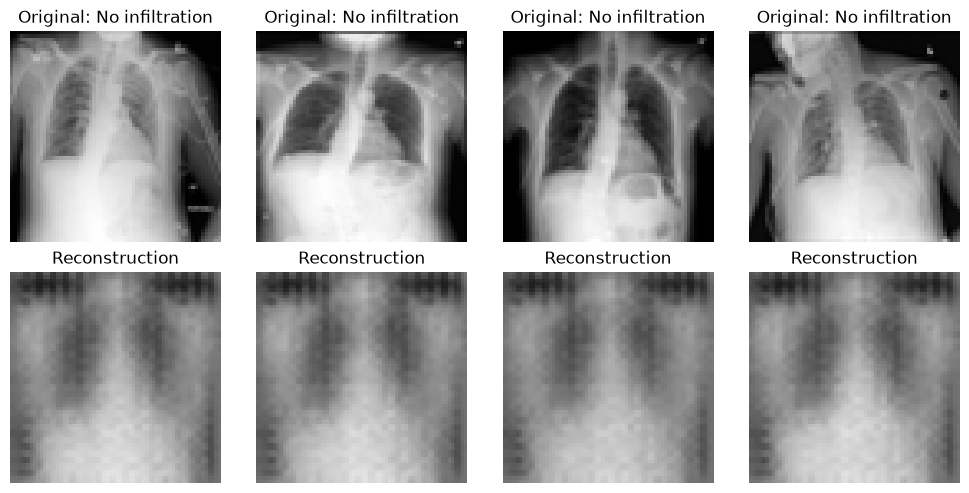

In [4]:
test_batch = next(iter(test_loader))
model.eval()
with torch.no_grad():
    result = model(**test_batch)

label_names = {0: "No infiltration", 1: "Infiltration"}
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for index in range(4):
    label = int(test_batch["label"][index].item())
    axes[0, index].imshow(test_batch["image"][index, 0], cmap="gray")
    axes[0, index].set_title(f"Original: {label_names[label]}")
    axes[0, index].axis("off")
    axes[1, index].imshow(
        result["reconstruction"][index, 0].cpu(), cmap="gray", vmin=0, vmax=1
    )
    axes[1, index].set_title("Reconstruction")
    axes[1, index].axis("off")
plt.tight_layout()
plt.show()

## 5. Generate images for both conditions

These samples are drawn from the trained decoder conditioned on the task's two label indices. Treat them as a model-behavior illustration; they are not validated synthetic clinical data.

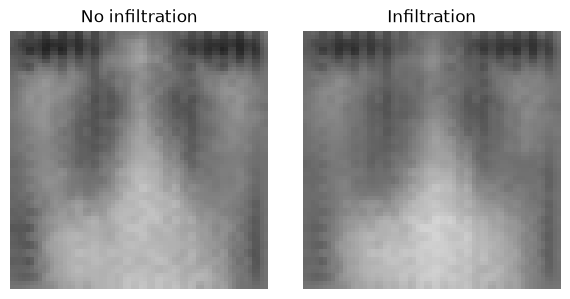

In [5]:
model.eval()
conditions = torch.tensor([0, 1], device=model.device)
with torch.no_grad():
    generated = model.generate(conditions=conditions)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for axis, image, label in zip(axes, generated, (0, 1)):
    axis.imshow(image[0].cpu(), cmap="gray", vmin=0, vmax=1)
    axis.set_title(label_names[label])
    axis.axis("off")
plt.tight_layout()
plt.show()

## What this example does and does not show

This notebook demonstrates that PyHealth's VAE can be wired to its ChestXray14 image pipeline and trained conditionally. Its short run and small development subset are for trying the workflow locally. To assess image fidelity or any downstream usefulness, use a suitable patient-level study design, train longer as appropriate, and evaluate the results with domain experts and held-out data.